In [23]:
import pickle
from pathlib import Path

import cv2
import matplotlib.animation as animation
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

In [24]:
periods_path = Path('../data/Karpicko/karpicko_periods_4_5_15.pkl')

with open(periods_path, 'rb') as f:
    periods = pickle.load(f)

images = [p['history'][-1]['image_name'] for p in periods]
irradiance = np.stack([p['target_irradiance'] for p in periods])
offline_outputs = np.load(f'{str(periods_path.parent / periods_path.stem)}_raw_output.npy')
online_outputs = np.load(f'{str(periods_path.parent / periods_path.stem)}_online_outputs.npy')
updates = np.load(f'{str(periods_path.parent / periods_path.stem)}_updates.npy')

len(images), len(irradiance), len(offline_outputs), len(online_outputs), len(updates)

(9346, 9346, 9346, 9346, 9346)

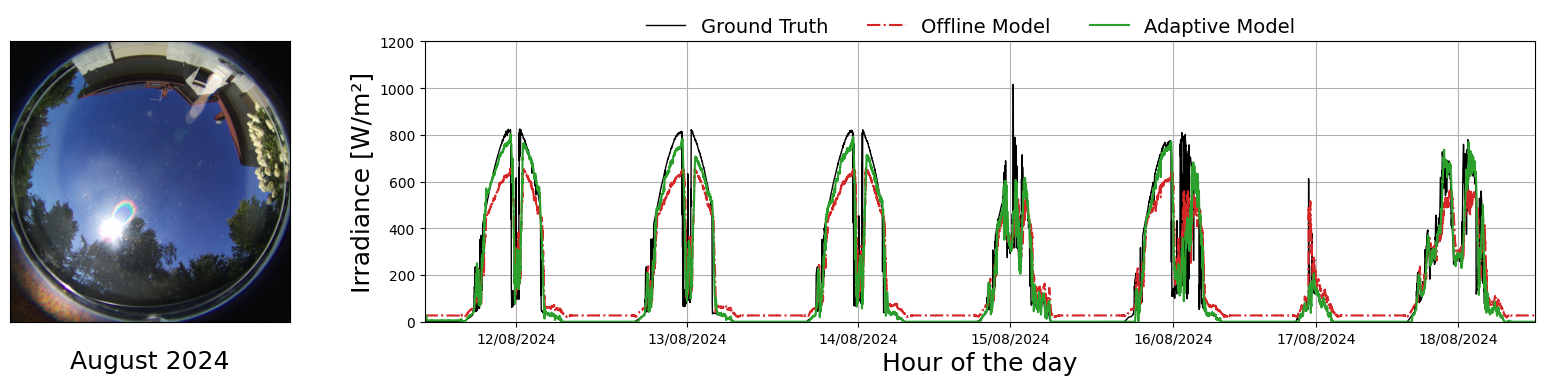

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4), gridspec_kw={'width_ratios': [1, 3]})

img_path = images[700]
year_month_day = img_path.split('/')[-1].split('__')[0]
year, month, day = year_month_day.split('_')
month_word = {
    '01': 'January', '02': 'February', '03': 'March', '04': 'April',
    '05': 'May', '06': 'June', '07': 'July', '08': 'August',
    '09': 'September', '10': 'October', '11': 'November', '12': 'December'
}[month]

ax[0].imshow(np.asarray(Image.open(img_path))[:, 254:-254])
ax[0].set_xticks([], [])
ax[0].set_yticks([], [])
ax[0].set_xlabel(f'{month_word} {year}', fontsize=18, labelpad=20)

ax[1].plot(irradiance, label="Ground Truth", color="black", linewidth=1)
ax[1].set_ylabel('Irradiance [W/m²]', fontsize=18)
ax[1].grid(True)
ax[1].set_ylim(0, (max(irradiance) // 200 + 1) * 200)
ax[1].set_xlim(0, len(irradiance))
# ax[1].set_xticks(np.arange(0, len(irradiance)+1, 60), np.arange(0, 25, 1));
ax[1].set_xlabel('Hour of the day', fontsize=18)
if periods_path.parent.name == 'Karpicko':
    # ax[1].set_ylim(0, 1200)
    ax[1].set_xticks([770, 2210, 3650, 4930, 6300, 7500, 8700], ['12/08/2024', '13/08/2024', '14/08/2024', '15/08/2024', '16/08/2024', '17/08/2024', '18/08/2024'])
elif periods_path.parent.name == 'Poznan':
    # ax[1].set_ylim(0, 800)
    ax[1].set_xticks([720, 2150, 3550, 5000, 6450, 7750, 9200, 10650], ['19/10/2024', '20/10/2024', '21/10/2024', '22/10/2024', '23/10/2024', '24/10/2024', '25/10/2024', '26/10/2024'])
elif periods_path.parent.name == 'Modena':
    # ax[1].set_ylim(0, 2000)
    ax[1].set_xticks([1050, 2450, 3950, 5400, 6800, 8250], ['07/06/2024', '08/06/2024', '09/06/2024', '10/06/2024', '11/06/2024', '12/06/2024'])
    # plt.legend(bbox_to_anchor=(0.8, 1.15), fontsize=14, ncol=3, frameon=False)
else:
    raise ValueError('Unknown dataset')

ax[1].plot(offline_outputs, label='Offline Model', linestyle='-.', color='tab:red')
ax[1].plot(online_outputs, label='Adaptive Model', color='tab:green')

plt.legend(loc='upper right', bbox_to_anchor=(0.8, 1.15), fontsize=14, ncol=3, frameon=False)
# plt.legend(loc='upper right', fontsize=14)
plt.tight_layout()
plt.savefig(f'{periods_path.parent.name}.png', dpi=300)

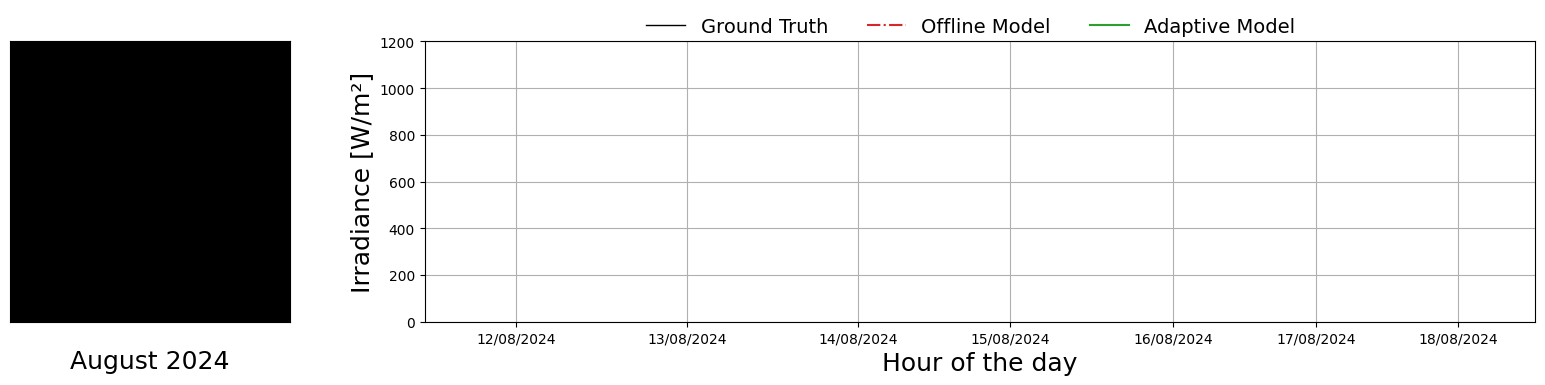

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4), gridspec_kw={'width_ratios': [1, 3]})

images_plotted = ax[0].imshow(np.asarray(Image.open(images[0]))[:, 254:-254])
ax[0].set_xticks([], [])
ax[0].set_yticks([], [])
ax[0].set_xlabel(f'{month_word} {year}', fontsize=18, labelpad=20)

lines_plotted = ax[1].plot([], label="Ground Truth", color="black", linewidth=1)
ax[1].set_ylabel('Irradiance [W/m²]', fontsize=18)
ax[1].grid(True)
ax[1].set_ylim(0, (max(irradiance) // 200 + 1) * 200)
ax[1].set_xlim(0, len(irradiance))
# ax[1].set_xticks(np.arange(0, len(irradiance)+1, 60), np.arange(0, 25, 1));
ax[1].set_xlabel('Hour of the day', fontsize=18)
if periods_path.parent.name == 'Karpicko':
    # ax[1].set_ylim(0, 1200)
    ax[1].set_xticks([770, 2210, 3650, 4930, 6300, 7500, 8700], ['12/08/2024', '13/08/2024', '14/08/2024', '15/08/2024', '16/08/2024', '17/08/2024', '18/08/2024'])
elif periods_path.parent.name == 'Poznan':
    # ax[1].set_ylim(0, 800)
    ax[1].set_xticks([720, 2150, 3550, 5000, 6450, 7750, 9200, 10650], ['19/10/2024', '20/10/2024', '21/10/2024', '22/10/2024', '23/10/2024', '24/10/2024', '25/10/2024', '26/10/2024'])
elif periods_path.parent.name == 'Modena':
    # ax[1].set_ylim(0, 2000)
    ax[1].set_xticks([1050, 2450, 3950, 5400, 6800, 8250], ['07/06/2024', '08/06/2024', '09/06/2024', '10/06/2024', '11/06/2024', '12/06/2024'])
else:
    raise ValueError('Unknown dataset')

offline_lines_plotted = ax[1].plot([], label='Offline Model', linestyle='-.', color='tab:red')
adaptive_lines_plotted = ax[1].plot([], label='Adaptive Model', color='tab:green')

line_plotted = lines_plotted[0]
offline_line_plotted = offline_lines_plotted[0]
adaptive_line_plotted = adaptive_lines_plotted[0]

# plt.legend(loc='upper right', fontsize=14)
plt.legend(loc='upper right', bbox_to_anchor=(0.8, 1.15), fontsize=14, ncol=3, frameon=False)
plt.tight_layout()

factor = 10

def animate(i):
    img = np.asarray(Image.open(images[i*factor]))[:, 254:-254]
    img = cv2.resize(img, (128, 128))
    images_plotted.set_array(img)
    line_plotted.set_data((np.arange(i*factor), irradiance[:i*factor]))
    offline_line_plotted.set_data((np.arange(i*factor), offline_outputs[:i*factor]))
    adaptive_line_plotted.set_data((np.arange(i*factor), online_outputs[:i*factor]))
    return images_plotted, line_plotted, offline_line_plotted, adaptive_line_plotted


ani = animation.FuncAnimation(fig, animate, repeat=True, frames=len(irradiance)//factor, interval=40)

# To save the animation using Pillow as a gif
writer = animation.PillowWriter(fps=25, metadata=dict(artist='Me'), bitrate=50000)
ani.save(f'{periods_path.parent.name}.gif', writer=writer)

# plt.show()